# 📊 Digital Marketing Campaign Conversion Prediction

## Business Understanding

**Problem Statement:** Businesses spend money across digital marketing channels such as email, social media, and paid advertising. However, not every customer who sees or interacts with a campaign completes a purchase. Marketing teams need a way to estimate which customers are more likely to convert so that they can make better campaign and budget decisions.

**Project Goal:** Build and evaluate machine-learning classification models that predict whether a customer will convert (`Conversion = 1`) or not convert (`Conversion = 0`) using demographic, campaign, and engagement information.

**Business value:** A reliable prediction can help marketing teams prioritize audiences, personalize campaigns, and reduce wasted advertising spend. Predictions are decision-support signals, not guarantees that a customer will purchase.

### Objectives
1. Data Exploration: Conduct comprehensive EDA using visualization techniques to understand feature distributions and relationships. 
2. Feature Engineering: Apply appropriate encoding techniques for categorical variables and consider feature scaling if necessary. 
3. Model Selection: Evaluate various classifiers including Decision Trees, Random Forests, Gradient Boosting methods, and others. 
4. Performance Evaluation: Use appropriate metrics such as F1 score, confusion matrix, and precision-recall curves to assess model performance. 
5. Visualization: Create clear and informative visualizations to communicate data insights and model performance. 
6. Code Quality: Ensure well-structured, commented Python code following best practices. 

### Dataset Overview

The dataset is expected to contain one row per customer/campaign observation and the following fields:

| Column | Meaning |
|---|---|
| `CustomerID` | Customer identifier; not used as a predictive feature |
| `Age`, `Gender`, `Income` | Customer demographic information |
| `CampaignChannel`, `CampaignType` | Marketing channel and campaign type |
| `AdSpend`, `ClickThroughRate` | Advertising spend and click-through rate |
| `WebsiteVisits`, `PagesPerVisit`, `TimeOnSite` | Website engagement |
| `SocialShares`, `EmailOpens`, `EmailClicks` | Campaign interaction measures |
| `PreviousPurchases`, `LoyaltyPoints` | Previous customer activity and loyalty |
| `AdvertisingPlatform`, `AdvertisingTool` | Platform/tool fields; drop if constant |
| `ConversionRate` | Potentially outcome-derived field; excluded from predictors to avoid leakage |
| `Conversion` | **Target:** 1 = converted, 0 = did not convert |

> **Important:** Confirm the dataset's actual column names and definitions before running the notebook. In particular, `ConversionRate` is excluded because it may contain information calculated using the conversion outcome. Do not use it unless you can verify it is genuinely available before the prediction is made.

---


## Table of Contents

1. [Import Libraries](#1-import-libraries)
2. [Load the Dataset](#2-load-the-dataset)
3. [Initial Data Exploration](#3-initial-data-exploration)
4. [Data Cleaning](#4-data-cleaning)
5. [Exploratory Data Analysis (EDA)](#5-exploratory-data-analysis-eda)
6. [Prepare Features and Target](#6-prepare-features-and-target)
7. [Train-Test Split and Preprocessing](#7-train-test-split-and-preprocessing)
8. [Model Evaluation Helper](#8-model-evaluation-helper)
9. [Logistic Regression](#9-logistic-regression)
10. [Random Forest](#10-random-forest)
11. [Support Vector Machine (SVM)](#11-support-vector-machine-svm)
12. [AdaBoost](#12-adaboost)
13. [Decision Tree](#13-decision-tree)
13. [XGBoost](#14-xgboost)
14. [Model Comparison and Selection](#15-model-comparison-and-selection)
15. [Feature Importance](#16-feature-importance)
16. [Save the Best Model](#17-save-the-best-model)
17. [Conclusion and Future Scope](#18-conclusion-and-future-scope)

---


## 1. Import Libraries

In [4]:
# Data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_sample_weight

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve,
    precision_recall_curve
)

# Saving the trained model
import joblib
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


## 2. Load the Dataset

In [5]:
campaign_data = pd.read_csv("digital_marketing_campaign_dataset(in).csv")
campaign_data.head()

,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1
2,8002,46,Female,88456,PPC,Awareness,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,2,8,2337,IsConfid,ToolConfid,1
3,8003,32,Female,44085,PPC,Conversion,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,2,0,2463,IsConfid,ToolConfid,1
4,8004,60,Female,83964,PPC,Conversion,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,6,8,4345,IsConfid,ToolConfid,1


## 3. Initial Data Exploration

Before modifying the dataset, inspect its dimensions, columns, data types, sample records, and summary statistics. This helps identify incorrect data types, unexpected values, and possible data-quality issues.


In [6]:
campaign_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CustomerID           8000 non-null   int64  
 1   Age                  8000 non-null   int64  
 2   Gender               8000 non-null   str    
 3   Income               8000 non-null   int64  
 4   CampaignChannel      8000 non-null   str    
 5   CampaignType         8000 non-null   str    
 6   AdSpend              8000 non-null   float64
 7   ClickThroughRate     8000 non-null   float64
 8   ConversionRate       8000 non-null   float64
 9   WebsiteVisits        8000 non-null   int64  
 10  PagesPerVisit        8000 non-null   float64
 11  TimeOnSite           8000 non-null   float64
 12  SocialShares         8000 non-null   int64  
 13  EmailOpens           8000 non-null   int64  
 14  EmailClicks          8000 non-null   int64  
 15  PreviousPurchases    8000 non-null   int64  
 16 

In [7]:
campaign_data.describe()

,CustomerID,Age,Income,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,Conversion
count,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,11999.50000,43.625500,84664.196750,5000.944830,0.154829,0.104389,24.751625,5.549299,7.727718,49.799750,9.476875,4.467375,4.485500,2490.268500,0.876500
std,2309.54541,14.902785,37580.387945,2838.038153,0.084007,0.054878,14.312269,2.607358,4.228218,28.901165,5.711111,2.856564,2.888093,1429.527162,0.329031
min,8000.00000,18.000000,20014.000000,100.054813,0.010005,0.010018,0.000000,1.000428,0.501669,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,9999.75000,31.000000,51744.500000,2523.221165,0.082635,0.056410,13.000000,3.302479,4.068340,25.000000,5.000000,2.000000,2.000000,1254.750000,1.000000
50%,11999.50000,43.000000,84926.500000,5013.440044,0.154505,0.104046,25.000000,5.534257,7.682956,50.000000,9.000000,4.000000,4.000000,2497.000000,1.000000
75%,13999.25000,56.000000,116815.750000,7407.989369,0.228207,0.152077,37.000000,7.835756,11.481468,75.000000,14.000000,7.000000,7.000000,3702.250000,1.000000
max,15999.00000,69.000000,149986.000000,9997.914781,0.299968,0.199995,49.000000,9.999055,14.995311,99.000000,19.000000,9.000000,9.000000,4999.000000,1.000000


In [8]:
campaign_data.shape

(8000, 20)

In [9]:
campaign_data.columns.tolist()

['CustomerID',
 'Age',
 'Gender',
 'Income',
 'CampaignChannel',
 'CampaignType',
 'AdSpend',
 'ClickThroughRate',
 'ConversionRate',
 'WebsiteVisits',
 'PagesPerVisit',
 'TimeOnSite',
 'SocialShares',
 'EmailOpens',
 'EmailClicks',
 'PreviousPurchases',
 'LoyaltyPoints',
 'AdvertisingPlatform',
 'AdvertisingTool',
 'Conversion']

## 4. Data Cleaning

We check missing values, duplicate records, target values, and constant columns. `CustomerID` is an identifier rather than a meaningful customer behaviour feature. `AdvertisingPlatform` and `AdvertisingTool` should be removed if they contain only one unique value.

`ConversionRate` is excluded from the model features because it may be derived from the outcome or may not be known at the time a prediction is made. This is a potential **data leakage** risk.


In [10]:
df = campaign_data.copy()
df.columns = df.columns.str.strip()  # Remove leading/trailing spaces from column names

null_values = df.isnull().sum()
null_values
print("Missing values by column:")
print(null_values[null_values > 0] if null_values.sum() else "No missing values found.")


Missing values by column:
No missing values found.


In [11]:
print(df["Conversion"].value_counts(dropna=False))

Conversion
1    7012
0     988
Name: count, dtype: int64


In [12]:
# Identify columns with only one unique non-null value
constant_columns = [
    col for col in df.columns
    if col != "Conversion" and df[col].nunique(dropna=True) <= 1
]
print("Constant columns to drop:", constant_columns)

# Drop identifier and constant columns if they exist
columns_to_drop = ["CustomerID"] + constant_columns
# ConversionRate is excluded due to possible target leakage
if "ConversionRate" in df.columns:
    columns_to_drop.append("ConversionRate")

columns_to_drop = list(dict.fromkeys(
    col for col in columns_to_drop if col in df.columns
))
df = df.drop(columns=columns_to_drop)

print("Dropped columns:", columns_to_drop)
print("Cleaned dataset shape:", df.shape)


Constant columns to drop: ['AdvertisingPlatform', 'AdvertisingTool']
Dropped columns: ['CustomerID', 'AdvertisingPlatform', 'AdvertisingTool', 'ConversionRate']
Cleaned dataset shape: (8000, 16)


In [13]:
df.isnull().sum()

Age                  0
Gender               0
Income               0
CampaignChannel      0
CampaignType         0
AdSpend              0
ClickThroughRate     0
WebsiteVisits        0
PagesPerVisit        0
TimeOnSite           0
SocialShares         0
EmailOpens           0
EmailClicks          0
PreviousPurchases    0
LoyaltyPoints        0
Conversion           0
dtype: int64

## 5. Exploratory Data Analysis (EDA)

EDA helps us understand the distribution of customers, campaign activity, and conversion outcomes before training models.


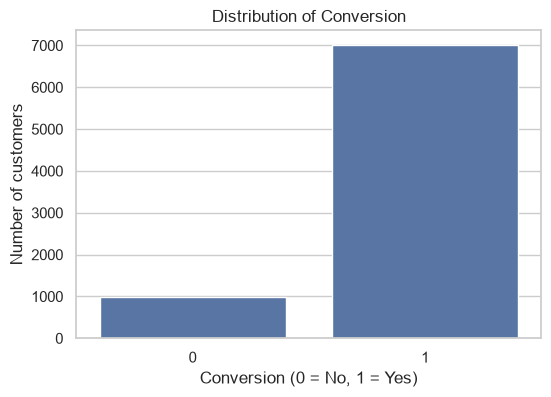

Conversion percentages:
Conversion
1    87.65
0    12.35
Name: proportion, dtype: float64


In [14]:
# Conversion distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Conversion")
ax.set_title("Distribution of Conversion")
ax.set_xlabel("Conversion (0 = No, 1 = Yes)")
ax.set_ylabel("Number of customers")
plt.show()

print("Conversion percentages:")
print((df["Conversion"].value_counts(normalize=True) * 100).round(2))

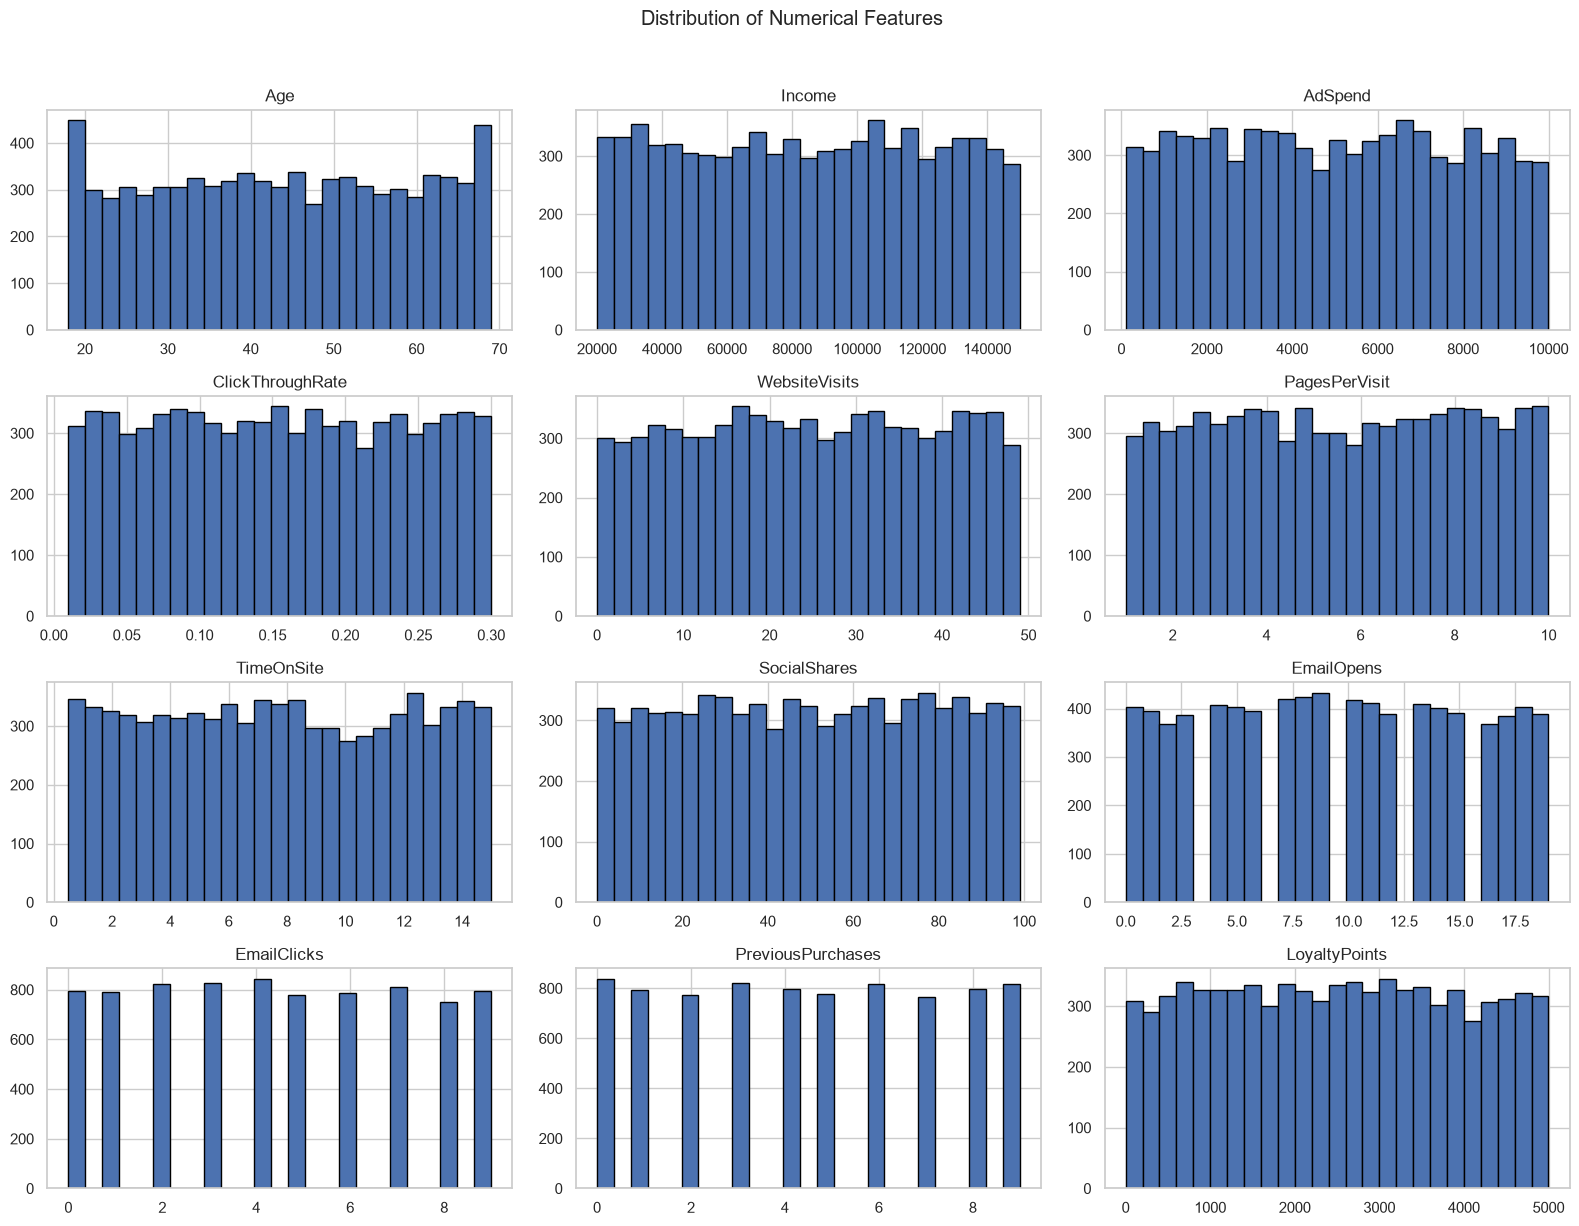

In [15]:
# Numeric feature distributions
numeric_for_eda = df.select_dtypes(include=np.number).columns.drop("Conversion", errors="ignore")

df[numeric_for_eda].hist(figsize=(16, 12), bins=25, edgecolor="black")
plt.suptitle("Distribution of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

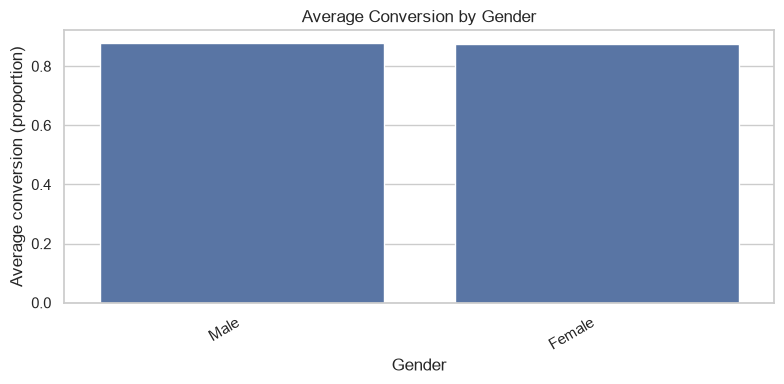

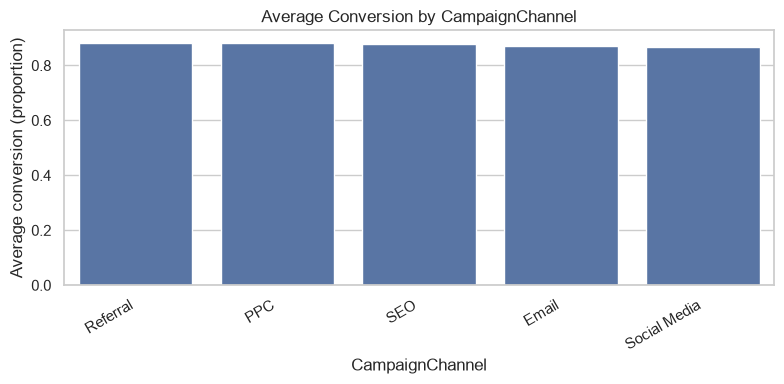

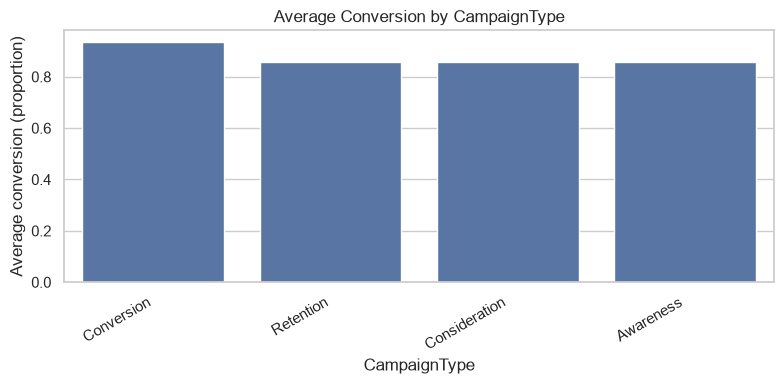

In [16]:
# Conversion rate by selected categorical variables
categorical_for_eda = [
    col for col in ["Gender", "CampaignChannel", "CampaignType"]
    if col in df.columns
]

for col in categorical_for_eda:
    conversion_by_category = df.groupby(col, dropna=False)["Conversion"].mean().sort_values(ascending=False)
    plt.figure(figsize=(8, 4))
    sns.barplot(x=conversion_by_category.index.astype(str),
                y=conversion_by_category.values)
    plt.title(f"Average Conversion by {col}")
    plt.xlabel(col)
    plt.ylabel("Average conversion (proportion)")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


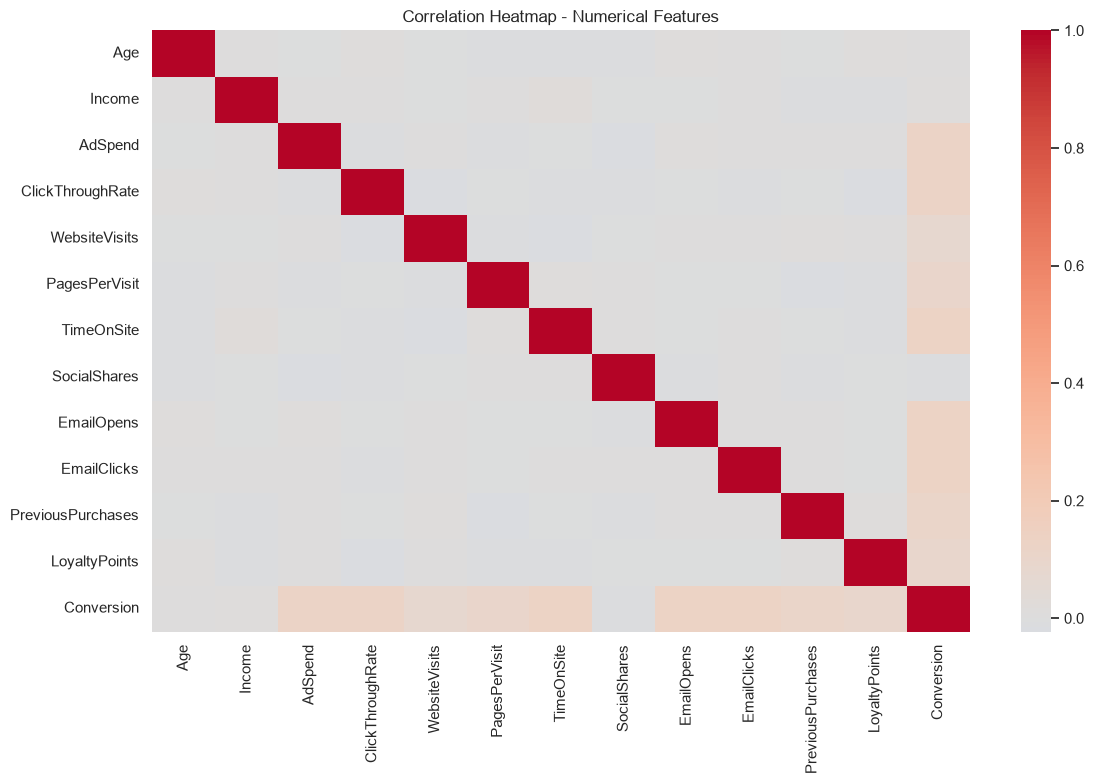

In [17]:
# Correlation heatmap for numerical columns
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap - Numerical Features")
plt.tight_layout()
plt.show()

### EDA Key Takeaways

After running the charts, write down the patterns you actually observe. For example:
- Which campaign channel has the highest observed conversion proportion?
- Does conversion appear to vary by campaign type?
- Are website visits, time on site, or email clicks associated with conversion?
- Is the target distribution imbalanced?

Do not assume that a relationship in a chart proves causation. Record the insights supported by your actual output.


## 6. Prepare Features and Target

`X` contains the input variables used to predict conversion. `y` contains the target column.

We explicitly exclude `CustomerID`, constant columns, and `ConversionRate` (possible leakage). The feature list is generated from the cleaned DataFrame, so the code stays aligned with the columns that remain after cleaning.


In [18]:
# Separate predictors and target
X = df.drop(columns=["Conversion"])
y = df["Conversion"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Features used:")
print(X.columns.tolist())

# Detect numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("\nNumerical features:", numeric_features)
print("\nCategorical features:", categorical_features)


Feature matrix shape: (8000, 15)
Target shape: (8000,)
Features used:
['Age', 'Gender', 'Income', 'CampaignChannel', 'CampaignType', 'AdSpend', 'ClickThroughRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints']

Numerical features: ['Age', 'Income', 'AdSpend', 'ClickThroughRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints']

Categorical features: ['Gender', 'CampaignChannel', 'CampaignType']


## 7. Train-Test Split and Preprocessing

We use an 80/20 train-test split. `stratify=y` keeps approximately the same target-class proportions in both sets.

The preprocessing steps are placed inside a scikit-learn pipeline:
- Numerical columns: fill missing values using the median, then standardize.
- Categorical columns: fill missing values using the most frequent category, then one-hot encode.

Fitting preprocessing only on the training data helps prevent data leakage. Using a pipeline also means the same preprocessing is automatically applied to new customer records in the Streamlit app.


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 6400
Testing rows: 1600


In [20]:
# Preprocessing for numerical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the transformations
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


## 8. Model Evaluation Helper

We evaluate every model on the same test set using:
- **Accuracy:** overall proportion of correct predictions.
- **Precision:** among predicted conversions, how many actually converted.
- **Recall:** among actual conversions, how many the model identified.
- **F1-score:** balance between precision and recall.
- **ROC-AUC:** ability to rank positive cases above negative cases.
- **PR-AUC / Average Precision:** useful when class distribution is imbalanced.

Because the dataset was previously observed to have an imbalanced target (about 87.65% class 1 and 12.35% class 0), accuracy alone can be misleading. Check both classes in the classification report and confusion matrix. The actual distribution is recalculated below from the loaded file.


In [21]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True).sort_index().mul(100).round(2))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).sort_index().mul(100).round(2))


Training target distribution:
Conversion
0    12.34
1    87.66
Name: proportion, dtype: float64

Test target distribution:
Conversion
0    12.38
1    87.62
Name: proportion, dtype: float64


In [22]:
results_summary = {}
trained_models = {}

def evaluate_model(model, name, X_test, y_test):
    """Evaluate a fitted pipeline and store comparable test metrics."""
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)
    roc_auc = roc_auc_score(y_test, probabilities)
    pr_auc = average_precision_score(y_test, probabilities)

    print(f"===== {name} =====")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision (Conversion=1): {precision:.4f}")
    print(f"Recall (Conversion=1): {recall:.4f}")
    print(f"F1-score (Conversion=1): {f1:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}")
    print(f"PR-AUC: {pr_auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, predictions, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions,
        display_labels=["No Conversion (0)", "Conversion (1)"],
        cmap="Blues"
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

    fpr, tpr, _ = roc_curve(y_test, probabilities)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve - {name}")
    plt.legend()
    plt.tight_layout()
    plt.show()

    results_summary[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    }


## 9. Logistic Regression

Logistic Regression is a classification algorithm and a useful baseline. It estimates the probability of a customer converting based on a weighted combination of input features.


===== Logistic Regression =====
Accuracy: 0.7319
Precision (Conversion=1): 0.9484
Recall (Conversion=1): 0.7340
F1-score (Conversion=1): 0.8275
ROC-AUC: 0.7698
PR-AUC: 0.9449

Classification Report:
              precision    recall  f1-score   support

           0       0.28      0.72      0.40       198
           1       0.95      0.73      0.83      1402

    accuracy                           0.73      1600
   macro avg       0.61      0.73      0.61      1600
weighted avg       0.87      0.73      0.77      1600



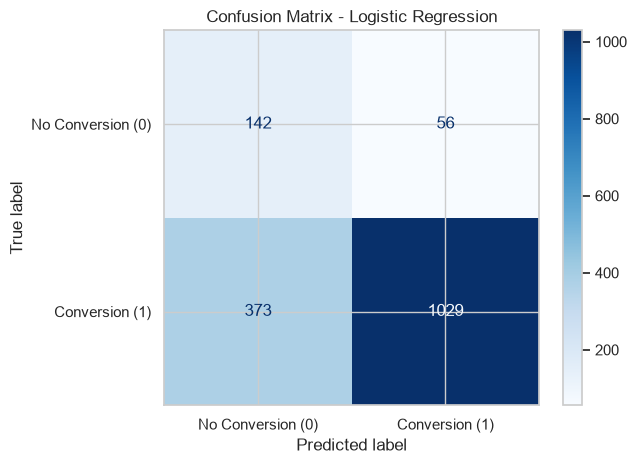

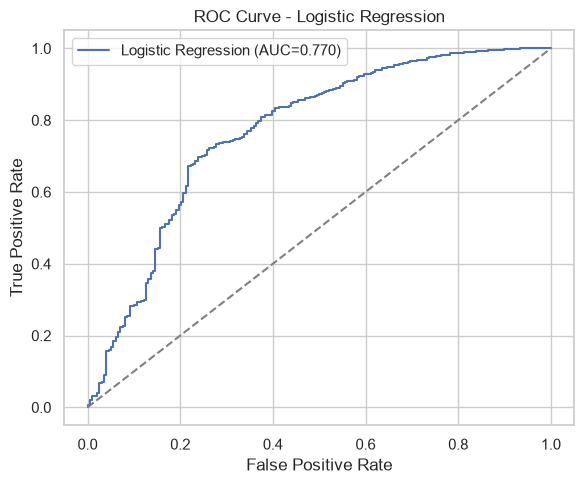

In [23]:
model_lr = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced",
                                      random_state=RANDOM_STATE))
])

model_lr.fit(X_train, y_train)
trained_models["Logistic Regression"] = model_lr
evaluate_model(model_lr, "Logistic Regression", X_test, y_test)


## 10. Random Forest

Random Forest combines predictions from many decision trees. It can capture non-linear relationships and interactions between customer and campaign features.


===== Random Forest =====
Accuracy: 0.9006
Precision (Conversion=1): 0.9124
Recall (Conversion=1): 0.9807
F1-score (Conversion=1): 0.9453
ROC-AUC: 0.7839
PR-AUC: 0.9411

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.33      0.45       198
           1       0.91      0.98      0.95      1402

    accuracy                           0.90      1600
   macro avg       0.81      0.66      0.70      1600
weighted avg       0.89      0.90      0.88      1600



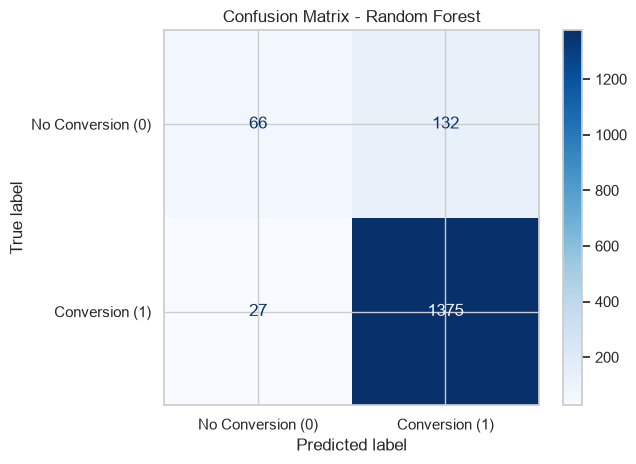

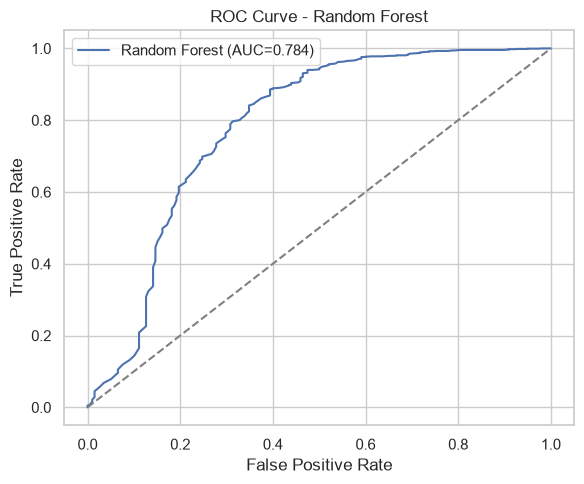

In [24]:
model_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

model_rf.fit(X_train, y_train)
trained_models["Random Forest"] = model_rf
evaluate_model(model_rf, "Random Forest", X_test, y_test)


## 11. Support Vector Machine (SVM)

Support Vector Machine finds a decision boundary that separates the classes. We use an RBF kernel to allow a non-linear boundary. `probability=True` enables conversion probability estimates for ROC-AUC and PR-AUC.


===== SVM =====
Accuracy: 0.8219
Precision (Conversion=1): 0.9326
Recall (Conversion=1): 0.8588
F1-score (Conversion=1): 0.8942
ROC-AUC: 0.7696
PR-AUC: 0.9436

Classification Report:
              precision    recall  f1-score   support

           0       0.36      0.56      0.44       198
           1       0.93      0.86      0.89      1402

    accuracy                           0.82      1600
   macro avg       0.65      0.71      0.67      1600
weighted avg       0.86      0.82      0.84      1600



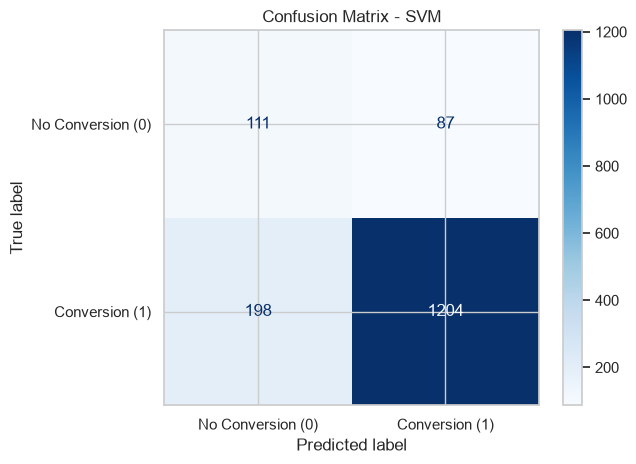

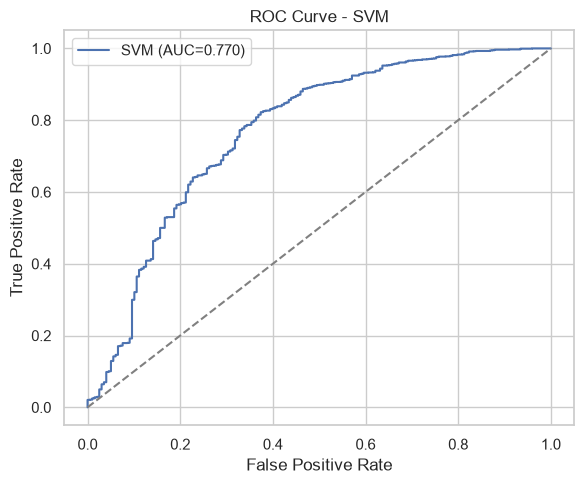

In [25]:
model_svm = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

model_svm.fit(X_train, y_train)
trained_models["SVM"] = model_svm
evaluate_model(model_svm, "SVM", X_test, y_test)


## 12. AdaBoost

AdaBoost (Adaptive Boosting) trains a sequence of weak learners. Later learners focus more on examples that earlier learners classified incorrectly.


===== AdaBoost =====
Accuracy: 0.8862
Precision (Conversion=1): 0.8871
Recall (Conversion=1): 0.9971
F1-score (Conversion=1): 0.9389
ROC-AUC: 0.8071
PR-AUC: 0.9489

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.10      0.18       198
           1       0.89      1.00      0.94      1402

    accuracy                           0.89      1600
   macro avg       0.86      0.55      0.56      1600
weighted avg       0.88      0.89      0.84      1600



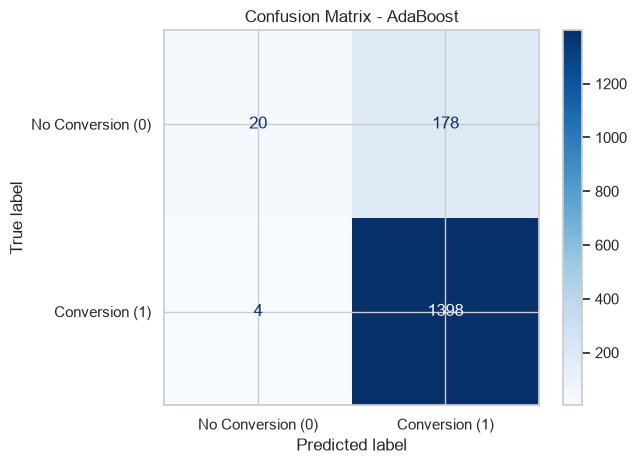

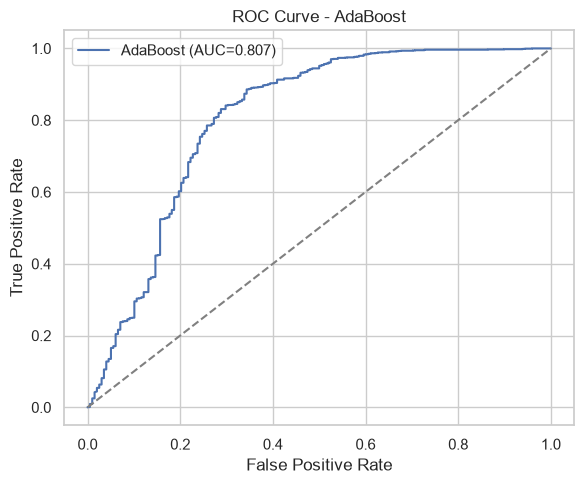

In [26]:
model_ada = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    ))
])

model_ada.fit(X_train, y_train)
trained_models["AdaBoost"] = model_ada
evaluate_model(model_ada, "AdaBoost", X_test, y_test)


## 13. Decision Tree

A Decision Tree is a supervised machine learning algorithm that makes predictions
by splitting data into smaller groups based on feature values.

It is included as an interpretable model to understand how customer demographics,
campaign details, and engagement activities influence conversion predictions.

===== Decision Tree =====
Accuracy: 0.7238
Precision (Conversion=1): 0.9286
Recall (Conversion=1): 0.7418
F1-score (Conversion=1): 0.8247
ROC-AUC: 0.7015
PR-AUC: 0.9284

Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.60      0.35       198
           1       0.93      0.74      0.82      1402

    accuracy                           0.72      1600
   macro avg       0.59      0.67      0.59      1600
weighted avg       0.84      0.72      0.77      1600



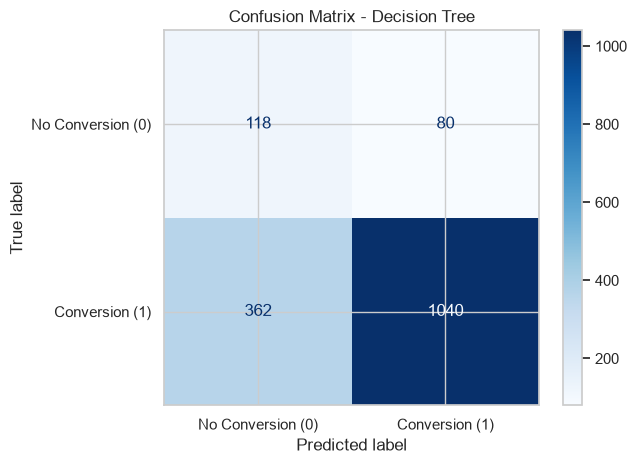

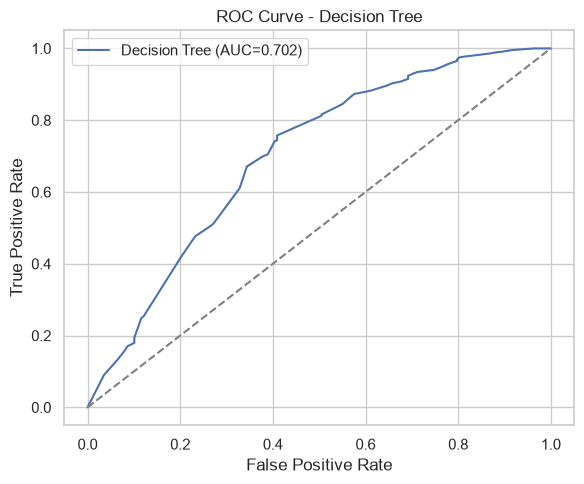

In [27]:
model_dt = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=6,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

model_dt.fit(X_train, y_train)
trained_models["Decision Tree"] = model_dt
evaluate_model(model_dt, "Decision Tree", X_test, y_test)

## 14. XGBoost

XGBoost is an optimized gradient-boosting algorithm. It builds trees sequentially and uses regularization to help control model complexity.

If XGBoost is not installed in your environment, run `%pip install xgboost` in a separate notebook cell and restart the kernel if required.


===== XGBoost =====
Accuracy: 0.9131
Precision (Conversion=1): 0.9163
Recall (Conversion=1): 0.9914
F1-score (Conversion=1): 0.9524
ROC-AUC: 0.8030
PR-AUC: 0.9498

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.36      0.51       198
           1       0.92      0.99      0.95      1402

    accuracy                           0.91      1600
   macro avg       0.89      0.68      0.73      1600
weighted avg       0.91      0.91      0.90      1600



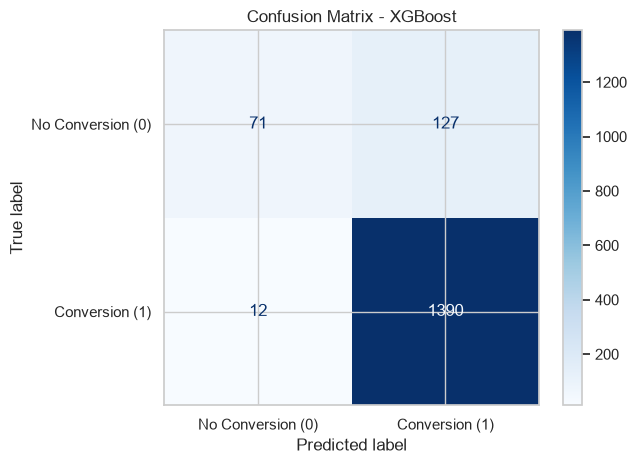

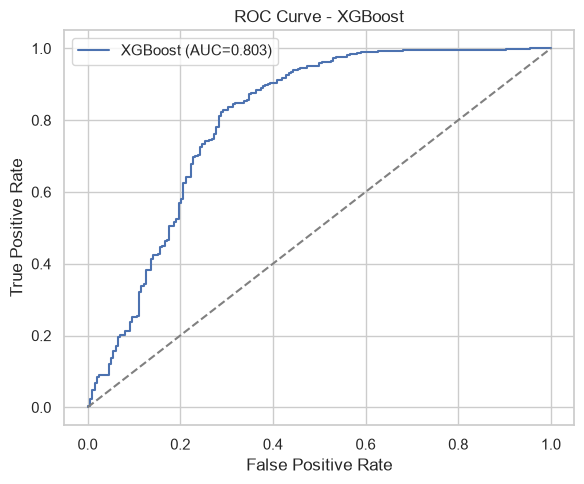

In [28]:
model_xgb = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=250,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

model_xgb.fit(X_train, y_train)
trained_models["XGBoost"] = model_xgb
evaluate_model(model_xgb, "XGBoost", X_test, y_test)


## 15. Model Comparison and Selection

All five models use the same train-test split and preprocessing approach. We compare their test metrics in one table.

For this project, **F1-score is used as the initial selection metric** because it balances precision and recall for customers predicted to convert. The final choice should also consider the campaign's real cost trade-off:
- Low precision means marketing spend may be wasted on customers who do not convert.
- Low recall means the campaign may miss customers who would have converted.

The best model should be chosen from the actual results below, not assumed in advance.


In [29]:
comparison_df = pd.DataFrame(results_summary).T
comparison_df = comparison_df.sort_values("F1-score", ascending=False)
comparison_df


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
XGBoost,0.913125,0.916282,0.991441,0.952381,0.803045,0.949773
Random Forest,0.900625,0.912409,0.980742,0.945342,0.783925,0.941074
AdaBoost,0.886250,0.887056,0.997147,0.938885,0.807063,0.948897
SVM,0.821875,0.932610,0.858773,0.894170,0.769557,0.943650
Logistic Regression,0.731875,0.948387,0.733951,0.827503,0.769773,0.944943
Decision Tree,0.723750,0.928571,0.741797,0.824742,0.701530,0.928375


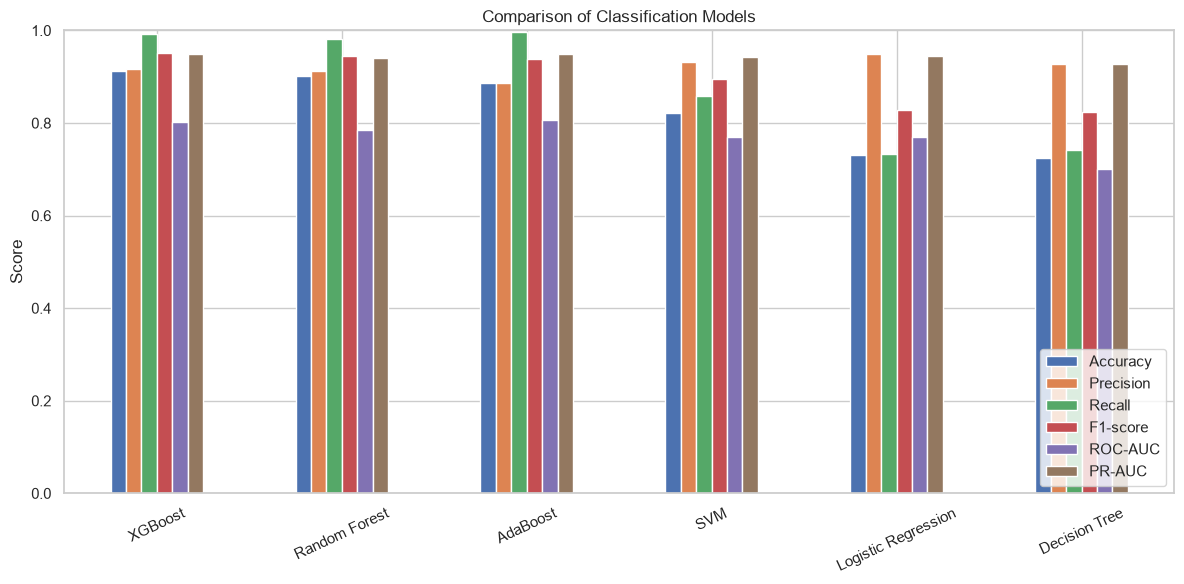

In [30]:
comparison_df[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]].plot(
    kind="bar", figsize=(12, 6), rot=25
)
plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [31]:
best_model_name = comparison_df["F1-score"].idxmax()
best_model = trained_models[best_model_name]

print("Best model based on F1-score:", best_model_name)
print(comparison_df.loc[best_model_name])


Best model based on F1-score: XGBoost
Accuracy     0.913125
Precision    0.916282
Recall       0.991441
F1-score     0.952381
ROC-AUC      0.803045
PR-AUC       0.949773
Name: XGBoost, dtype: float64


## 16. Feature Importance

Tree-based models provide feature-importance scores. These can help explain which input variables the model relied on most. Importance indicates predictive usefulness in the fitted model; it does not prove that a feature causes conversion.

The following cell displays feature importance when the selected model is Random Forest, AdaBoost, or XGBoost. Logistic Regression and SVM require different interpretation methods.


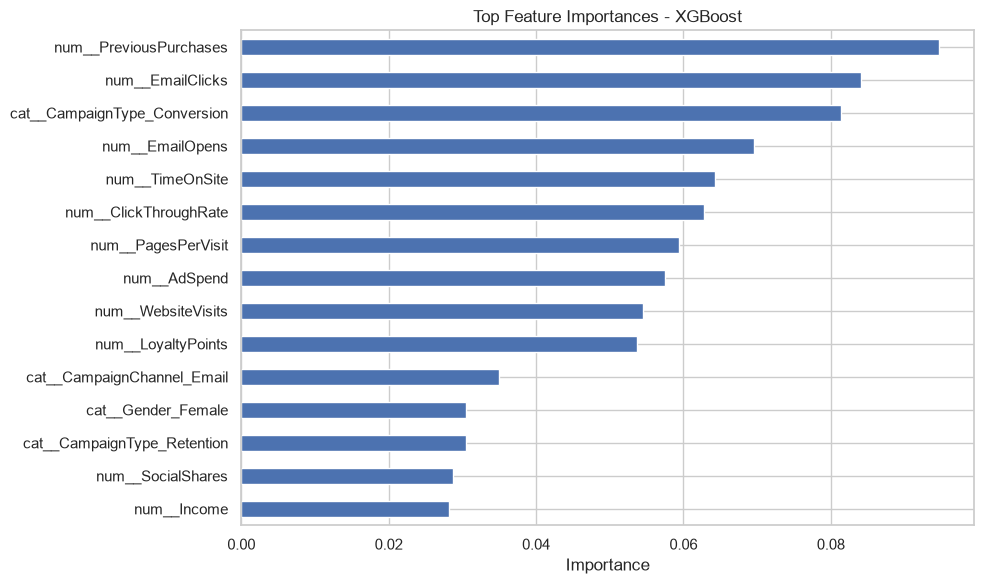

In [32]:
# Feature importance for tree-based selected models
selected_classifier = best_model.named_steps["classifier"]

if hasattr(selected_classifier, "feature_importances_"):
    transformed_feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
    importances = pd.Series(
        selected_classifier.feature_importances_,
        index=transformed_feature_names
    ).sort_values(ascending=False).head(15)

    plt.figure(figsize=(10, 6))
    importances.sort_values().plot(kind="barh")
    plt.title(f"Top Feature Importances - {best_model_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print(
        f"{best_model_name} does not expose tree-based feature_importances_. "
        "Use permutation importance or model-specific coefficients for interpretation."
    )


## 17. Save the Best Model

We save the **entire fitted pipeline**, including imputers, scaling, one-hot encoding, and the selected classifier. This is important: the Streamlit app must load this pipeline and pass it raw input columns in the same format as `X`. Do not separately encode or scale the app inputs when using this saved pipeline.


In [33]:
model_artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "input_features": X.columns.tolist(),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features
}

joblib.dump(model_artifact, "digital_marketing_conversion_model.pkl")
comparison_df.to_csv("model_comparison_results.csv")

print("Saved model: digital_marketing_conversion_model.pkl")
print("Saved comparison: model_comparison_results.csv")


Saved model: digital_marketing_conversion_model.pkl
Saved comparison: model_comparison_results.csv


In [34]:
# Quick reload test
loaded_artifact = joblib.load("digital_marketing_conversion_model.pkl")
loaded_model = loaded_artifact["model"]

# Predict a small sample from the test set to verify the saved pipeline
sample_predictions = loaded_model.predict(X_test.head(5))
sample_probabilities = loaded_model.predict_proba(X_test.head(5))[:, 1]

print("Predictions:", sample_predictions)
print("Conversion probabilities:", np.round(sample_probabilities, 3))


Predictions: [1 1 1 0 1]
Conversion probabilities: [0.958 0.993 0.974 0.219 0.974]


## 18. Conclusion and Future Scope

### Conclusion

Complete this section after running the notebook. Include:
- The number of records and input features used.
- The main patterns observed during EDA.
- The five algorithms evaluated: Logistic Regression, Random Forest, SVM, AdaBoost, and XGBoost.
- The selected model and its measured test metrics.
- How the model could support campaign audience prioritization.

### Limitations
- Model performance depends on the quality and representativeness of the dataset.
- Conversion predictions do not directly calculate revenue, profit, or Return on Ad Spend (ROAS). Revenue and campaign cost data would be needed for those calculations.
- Correlation and feature importance do not establish causation.
- The probability output should be monitored and calibrated before being used for high-impact budget decisions.

### Future Scope
1. Tune hyperparameters using cross-validation and `RandomizedSearchCV` or `GridSearchCV`.
2. Test decision thresholds based on campaign costs and business priorities.
3. Add revenue and campaign-cost data to estimate expected value and ROAS.
4. Monitor model performance as customer behaviour and campaign trends change.
5. Deploy the saved pipeline through a Streamlit interface for interactive predictions.
